# LIVRABLE 1 — MODÉLISATION DU PROBLÈME

**Projet CesiCDP / ADEME**

**Groupe 1 : Sandago, Emmanuel, Thomas**

Ce notebook présente une première modélisation du problème de tournées de livraison selon les quatre points de la grille d'évaluation :

- Identification du problème
- Définition mathématique du problème
- Complexité
- Méthode de résolution

# INTRODUCTION

Dans le cadre de sa politique de réduction de la consommation d'énergie et des émissions de gaz à effet de serre, l'ADEME souhaite soutenir de nouvelles solutions de mobilité.

CesiCDP propose d'étudier l'optimisation de tournées de livraison. Le but est de planifier les trajets d'une flotte de camions desservant un ensemble de clients, tout en **minimisant la durée totale des tournées**.

Le temps de parcours doit également tenir compte de la variabilité du trafic selon les différentes tranches horaires.

# I. Identification du problème

## I.1 Problème étudié

Le problème consiste à organiser les tournées d'une flotte de $k$ camions.

Chaque camion part d'un dépôt, dessert plusieurs clients puis revient au dépôt.

La solution doit permettre :

- de desservir tous les clients ;
- de respecter la capacité des camions ;
- de tenir compte du trafic ;
- de minimiser la durée totale des tournées.

## I.2 Type de problème

Le problème appartient à la famille des **Vehicle Routing Problems (VRP)**.

La présence d'une capacité maximale pour les camions rapproche le problème du **Capacitated Vehicle Routing Problem (CVRP)**.

La prise en compte de temps de trajet variables selon l'heure ajoute une dépendance temporelle au problème.

Si l'on réduit la flotte à un seul camion et que l'on retire les contraintes supplémentaires, on retrouve le **Traveling Salesperson Problem (TSP)**.

## I.3 Hypothèses retenues

Pour cette première modélisation, nous retenons les hypothèses suivantes :

- un seul dépôt ;
- une flotte de $k$ camions de capacité identique ;
- chaque client doit être livré exactement une fois ;
- chaque camion utilisé part du dépôt et y revient ;
- chaque client possède une demande connue ;
- les temps de trajet dépendent du trafic ;
- les fenêtres temporelles ne sont pas intégrées dans la version de base.

Les fenêtres de livraison pourront être ajoutées dans une version avancée.

# II. Définition mathématique du problème

## II.1 Modélisation sous forme de graphe

Le réseau de livraison est représenté par un graphe orienté :

$$
G=(V,A)
$$

avec :

- $V=\{0,1,\ldots,n\}$ : ensemble des sommets ;
- $0$ : dépôt ;
- $C=\{1,\ldots,n\}$ : ensemble des clients ;
- $A$ : ensemble des arcs possibles entre les sommets.

Un arc $(i,j)$ représente la possibilité de se déplacer du sommet $i$ vers le sommet $j$.

## II.2 Paramètres

| Symbole | Signification |
|---|---|
| $K$ | Ensemble des camions |
| $Q$ | Capacité maximale d'un camion |
| $q_i$ | Demande du client $i$ |
| $T_{ij}(t)$ | Temps de trajet de $i$ vers $j$ pour un départ à l'instant $t$ |
| $d_k$ | Heure de départ du camion $k$ |
| $r_k$ | Heure de retour du camion $k$ |

## II.3 Variables de décision

La principale variable de décision est :

$$
x_{ijk}=
\begin{cases}
1 & \text{si le camion }k\text{ va directement de }i\text{ vers }j,\\
0 & \text{sinon.}
\end{cases}
$$

On utilise également :

$$
t_{ik}\geq 0
$$

qui représente l'heure d'arrivée du camion $k$ chez le client $i$.

## II.4 Fonction objectif

Nous souhaitons minimiser la somme des durées des tournées.

Pour un camion $k$, la durée de sa tournée est :

$$
r_k-d_k
$$

La fonction objectif retenue est donc :

$$
\boxed{
\min \sum_{k\in K}(r_k-d_k)
}
$$

Cette formulation représente directement le temps écoulé entre le départ et le retour de chaque camion.

## II.5 Contraintes principales

### II.5.1 Chaque client est visité exactement une fois

Pour tout client $i$ :

$$
\sum_{k\in K}\sum_{\substack{j\in V\\j\neq i}}x_{ijk}=1
$$

Cette contrainte garantit qu'un seul camion dessert chaque client.

### II.5.2 Conservation du flux

Pour chaque client $i$ et chaque camion $k$ :

$$
\sum_{\substack{j\in V\\j\neq i}}x_{jik}
=
\sum_{\substack{j\in V\\j\neq i}}x_{ijk}
$$

Un camion qui arrive chez un client doit également en repartir.

### II.5.3 Départ et retour au dépôt

Chaque camion utilisé doit partir du dépôt et y revenir.

Pour chaque camion $k$, le nombre de départs du dépôt doit être égal au nombre de retours :

$$
\sum_{j\in C}x_{0jk}
=
\sum_{i\in C}x_{i0k}
$$

Un camion non utilisé peut ne réaliser aucune tournée.

### II.5.4 Respect de la capacité

Pour chaque camion $k$ :

$$
\sum_{i\in C} q_i
\left(
\sum_{\substack{j\in V\\j\neq i}}x_{ijk}
\right)
\leq Q
$$

La somme des demandes des clients desservis par un camion ne doit pas dépasser sa capacité maximale.

### II.5.5 Cohérence des temps de trajet

Si le camion $k$ va du client $i$ vers le client $j$, alors l'heure d'arrivée chez $j$ dépend :

- de l'heure d'arrivée chez $i$ ;
- du temps de trajet entre $i$ et $j$ ;
- du trafic au moment du départ.

On exprime cette logique par :

$$
x_{ijk}=1
\Rightarrow
t_{jk}\geq t_{ik}+T_{ij}(t_{ik})
$$

Le même principe permet de relier :

- l'heure de départ $d_k$ au premier client ;
- les heures de passage entre les clients ;
- le dernier client à l'heure de retour $r_k$.

La forme linéarisée précise de cette dépendance temporelle sera fixée lors de l'implémentation.

### II.5.6 Absence de sous-tours

Une solution ne doit pas contenir de boucle de clients indépendante du dépôt.

Par exemple, une boucle :

$$
1\rightarrow2\rightarrow3\rightarrow1
$$

sans passage par le dépôt doit être interdite.

Une contrainte d'élimination des sous-tours devra donc être intégrée au modèle.

# III. Étude de complexité

## III.1 La question de décision

**Existe-t-il au plus k tournées qui servent tous les clients, respectent les capacités et dont la durée totale est au plus K ?**

K est une limite donnée en entrée. Répondre OUI ne demande pas de prouver que les tournées sont optimales.

## III.2 Pourquoi le problème est dans NP
Le certificat est la liste ordonnée des clients de chaque tournée. Nous vérifions les visites uniques, les arcs autorisés, les charges, le nombre de camions, les retours et la durée totale.

Il y a au plus n tournées non vides et chaque client apparaît une fois. La description des tournées est donc de taille polynomiale. Avec des durées données sous une représentation finie permettant des calculs en temps polynomial, ces contrôles se font en temps polynomial dans la taille des données, y compris leur encodage numérique. **La version de décision appartient donc à NP.**

Cela concerne les données initiales du problème ; il n'est pas nécessaire de construire l'immense liste R pour vérifier une proposition.

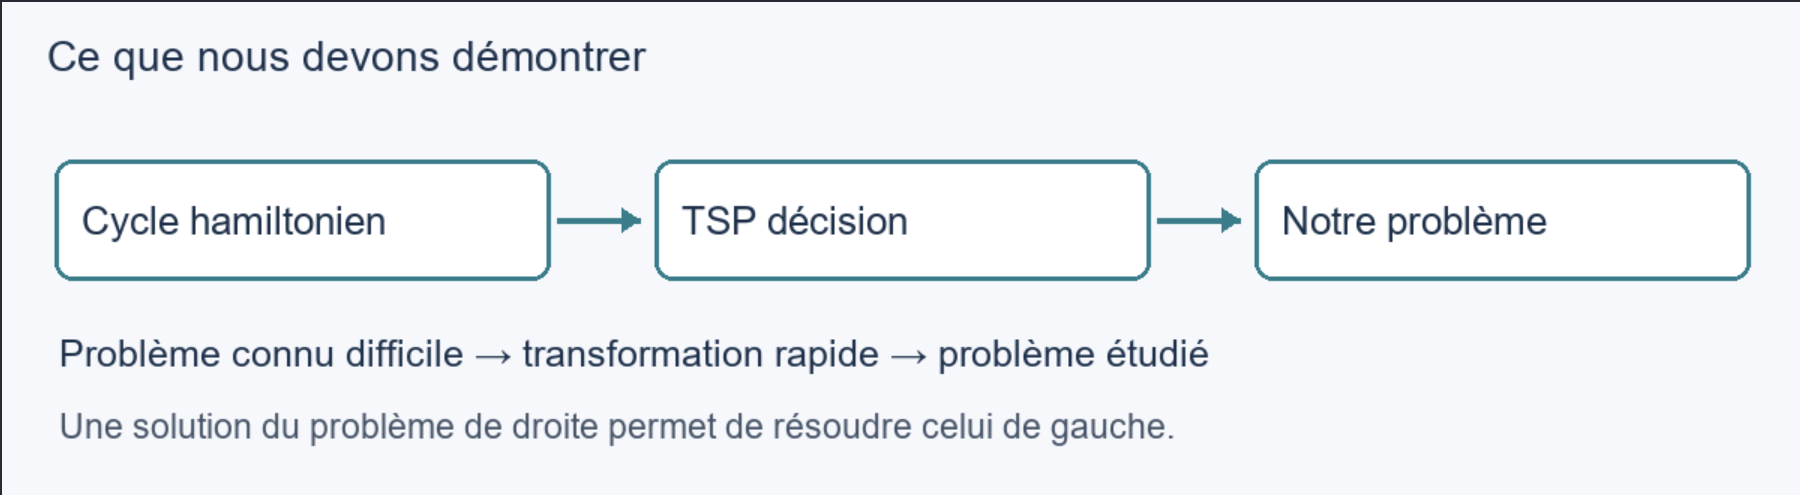

## III.3 Pourquoi le problème est NP-difficile
**Le sens de la preuve compte : nous transformons un problème déjà connu difficile vers notre problème.**

**Étape A — Cycle hamiltonien vers TSP décision.** Le problème du cycle hamiltonien, connu NP-complet [2], demande s'il existe un cycle visitant chaque sommet exactement une fois. À partir d'un graphe de N sommets, on construit un graphe complet : coût 1 pour une liaison existante, coût 2 pour une liaison ajoutée. On fixe la limite à N.

• Si le graphe initial possède un cycle hamiltonien, ses N liaisons coûtent chacune 1 : la tournée coûte N.  
• Si une tournée du nouveau graphe coûte au plus N, ses N liaisons doivent toutes coûter 1. Elle correspond donc à un cycle hamiltonien du graphe initial.

La construction examine au plus un nombre quadratique de paires : elle est polynomiale. Les coûts 1 et 2 respectent aussi l'inégalité triangulaire : une liaison directe coûte au plus 2, passer par un troisième sommet coûte au moins 1 + 1. La difficulté existe donc même dans le cas métrique.

**Étape B — TSP décision vers notre problème de livraison.** On choisit un sommet comme dépôt et les autres comme clients. On fixe un seul camion, une demande de 1 par client et une capacité égale au nombre de clients. On utilise les coûts du TSP comme durées, constantes quelle que soit l'heure, et on garde la même limite K.

Une tournée TSP de coût au plus K existe **si et seulement si** une solution de livraison de durée au plus K existe dans cette instance. La capacité ne bloque aucune tournée ; le camion doit visiter tous les clients et revenir au dépôt. La transformation est polynomiale.

Le problème avec trafic contient le cas sans variation de trafic. Il est donc au moins aussi difficile que ce cas particulier. Ce raisonnement utilise l'hypothèse que k est une donnée pouvant valoir 1.

## III.4 Conclusion sur la complexité
**Notre problème de décision est NP-complet : il est dans NP et NP-difficile. Le problème d'optimisation est NP-difficile.**

Cela ne signifie pas qu'une petite instance est impossible à résoudre. Cela ne prouve pas non plus que tout algorithme doit prendre un temps exponentiel. Aucun algorithme exact polynomial général n'est connu ; en trouver un pour ce problème impliquerait P = NP [2, 5].

# IV. Méthode de résolution envisagée

## IV.1 Conséquence de la complexité

L'étude de complexité montre que notre problème est NP-difficile.

Pour des instances de grande taille, une méthode exacte peut donc devenir trop coûteuse en temps de calcul.

Le projet devra alors s'orienter vers des méthodes permettant d'obtenir une solution satisfaisante dans un temps raisonnable.

## IV.2 Heuristiques

Une heuristique est une méthode permettant de construire rapidement une solution réalisable sans garantir qu'elle soit optimale.

Elle pourra notamment être utilisée pour obtenir une première solution au problème de tournées.

## IV.3 Métaheuristiques

Une métaheuristique est une méthode plus générale permettant d'améliorer ou d'explorer différentes solutions afin d'éviter de rester bloqué sur une solution localement intéressante.

Plusieurs métaheuristiques existent, par exemple :

- le recuit simulé ;
- la recherche taboue ;
- les algorithmes génétiques ;
- les colonies de fourmis.

Le choix précis de la méthode sera effectué dans la suite du projet après étude et comparaison de ces différentes approches.

# V. Conclusion

Le problème étudié est une variante du **Vehicle Routing Problem**, intégrant plusieurs camions de capacité identique et des temps de trajet dépendant du trafic.

Le problème a été représenté par un graphe et une première formulation mathématique a été proposée avec :

- des variables de décision ;
- une fonction objectif basée sur la différence entre heure de retour et heure de départ ;
- des contraintes de visite, de capacité, de continuité et de temps.

Le lien avec le TSP permet de conclure que le problème est **NP-difficile**.

La suite du projet consistera à préciser la méthode de résolution, l'implémenter en Python puis étudier expérimentalement ses performances.

# VI. Références bibliographiques

-Workshop CESI Graphes et Modélisation

-Workshop CESI Problème NP-Complet

-Workshop CESI Méthodes Exactes